# Exercise 2.1: Integral evaluation
> **Goal**: Evaluate the following integral via MC methods
>$$I = \int_0^1 \frac{\pi}{2}\cos(\pi x/2) dx = 1$$
>  - Sampling a uniform distribution in $[0,1)$
>  - Using importance sampling, still in $[0,1)$
>
>Plot both results with a large number of throws ($M \geq 10^4$) as a function of the number of blocks $N$

First, as in exercise 1.1, we evaluate the integral sampling a uniform distribution:

In [1]:
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import math

def rng(N):
  output = subprocess.run(["./run", str(N)],
                          cwd="./rannyu_rng",
                          capture_output=True,
                          text=True)
  return np.fromstring(output.stdout, sep='\n')

def error(av, av2, n):
  return math.sqrt( (av2 - av * av) / max(n-1, 1) )

def f(x):
  return (np.pi / 2) * np.cos(np.pi * x / 2)

N_blocks = 100
N_throws_per_block = int(1e4)
values = f(rng(N_throws_per_block * N_blocks))

estimates = np.zeros(N_blocks)
blocks_av = np.zeros(N_blocks)
blocks_av2 = np.zeros(N_blocks)
error_progr = np.zeros(N_blocks)

for block in range(N_blocks):
  for i in range(N_throws_per_block):
    estimates[block] += values[block * N_throws_per_block + i]
  estimates[block] /= N_throws_per_block

  for i in range(N_blocks - block):
    blocks_av[block + i] += estimates[block]
    blocks_av2[block + i] += estimates[block]**2

for block in range(N_blocks):
  blocks_av[block] /= block + 1
  blocks_av2[block] /= block + 1
  error_progr[block] = error(blocks_av[block], blocks_av2[block], block + 1)

Then, for importance sampling, we can choose a decreasing linear distribution $p(x) = 2(1-x)$. We add it to our random sampler as
```cpp
double Random::linear_decreasing() {
  return 1 - std::sqrt(1 - rannyu());
}
```

and use it to compute and plot:

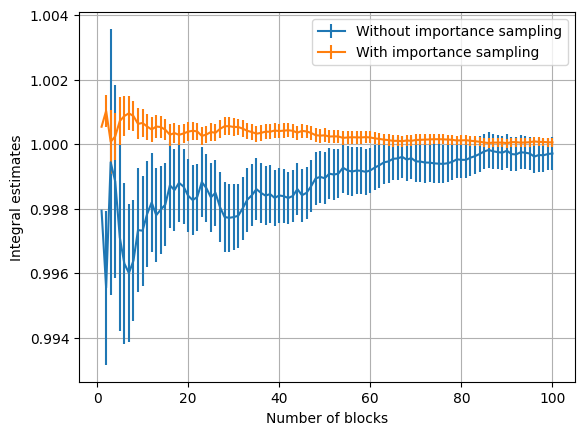

In [2]:
def rng_linear(N):
  output = subprocess.run(["./run", str(N), "linear"],
                          cwd="./rannyu_rng",
                          capture_output=True,
                          text=True)
  return np.fromstring(output.stdout, sep='\n')

samples_is = rng_linear(N_blocks * N_throws_per_block)
# values_is = f(samples) / (2 * max((1 - samples), 1e-6))
values_is = np.zeros(N_blocks * N_throws_per_block)
for i in range(N_blocks * N_throws_per_block):
  values_is[i] = f(samples_is[i]) / (2 * max(1-samples_is[i], 1e-8))

estimates_is = np.zeros(N_blocks)
blocks_av_is = np.zeros(N_blocks)
blocks_av2_is = np.zeros(N_blocks)
error_progr_is = np.zeros(N_blocks)

for block in range(N_blocks):
  for i in range(N_throws_per_block):
    estimates_is[block] += values_is[block * N_throws_per_block + i]
  estimates_is[block] /= N_throws_per_block

  for i in range(N_blocks - block):
    blocks_av_is[block + i] += estimates_is[block]
    blocks_av2_is[block + i] += estimates_is[block]**2

for block in range(N_blocks):
  blocks_av_is[block] /= block + 1
  blocks_av2_is[block] /= block + 1
  error_progr_is[block] = error(blocks_av_is[block], blocks_av2_is[block], block + 1)

plt.errorbar(np.arange(1, N_blocks+1), blocks_av, yerr=error_progr, label="Without importance sampling")
plt.errorbar(np.arange(1, N_blocks+1), blocks_av_is, yerr=error_progr_is, label="With importance sampling")
plt.xlabel("Number of blocks")
plt.ylabel("Integral estimates")
plt.grid(True)
plt.legend()

# Exercise 2.2: 3D Random Walk
> **Goal**: Repeat many times (e.g. $10^4$) the simulation of a 3D RW starting at the origin
>  - on a cubic lattice with lattice constant $a$
>  - in the continuum (fix the step $a$, but sample uniformly the 3D direction)
>
> For both, plot $\sqrt{\langle |\vec{r}_N|^2 \rangle_{RW}}$, with its statistical uncertainties, as function of the step $a \in [0,10^2]$.
>
> Fit both results with a diffusion function $f(N)=k\sqrt{N}$.


*Suggestion*: divide your $M$ throws into a reasonable number of blocks, compute $\sqrt{\langle |\vec{r}_N|^2 \rangle_{RW}}$ as function of the step $i\in [0,10^2]$ in each block and use these values (for fixed $i$) to obtain the average value and its statistical uncertainty.

We can add to the `Random` class two methods for simulating RW on a 3D lattice and in 3D continuum space (*fixed step size, random 3D direction*) as
```cpp
void Random::rw_lattice(double a, int N_steps) {
  int x = 0, y = 0, z = 0;
  std::cout << 0 << " ";

  for (int i = 0; i < N_steps; i++) {
    double rand = 6*rannyu();
    if (rand < 1.0) {
      x++;
    } else if (rand < 2.0) {
      x--;
    } else if (rand < 3.0) {
      y++;
    } else if (rand < 4.0) {
      y--;
    } else if (rand < 5.0) {
      z++;
    } else {
      z--;
    }
    std::cout << std::abs(a) * std::sqrt(x*x + y*y + z*z) << " ";
  }
  std::cout << std::endl;
}

void Random::rw_continuum(double a, int N_steps) {
  double x = 0, y = 0, z = 0;
  std::cout << 0 << " ";

  for (int i = 0; i < N_steps; i++) {
    double theta = pi * (rannyu() - 0.5); // CHANGE!
    double phi = 2 * pi * rannyu();

    x += std::cos(theta) * std::cos(phi);
    y += std::cos(theta) * std::sin(phi);
    z += std::sin(theta);

    std::cout << std::abs(a) * std::sqrt(x*x + y*y + z*z) << " ";
  }
  std::cout << std::endl;
}
```

These methods keep the details of the trajectory and only output the succession of distances from the origin, which we can capture in Python:

In [3]:
import subprocess
import matplotlib.pyplot as plt
import numpy as np

def rw_lattice(N_reps, a, N_steps):
  output = subprocess.run(["./run", str(N_reps), "rw_lattice", str(a), str(N_steps)],
                          cwd="./rannyu_rng",
                          capture_output=True,
                          text=True)
  return np.array([list(map(float, line.split())) for line in output.stdout.strip().split('\n')])

def rw_continuum(N_reps, a, N_steps):
  output = subprocess.run(["./run", str(N_reps), "rw_continuum", str(a), str(N_steps)],
                          cwd="./rannyu_rng",
                          capture_output=True,
                          text=True)
  return np.array([list(map(float, line.split())) for line in output.stdout.strip().split('\n')])

N_blocks = 10
N_reps_per_block = int(1e2)
a = 1.0
N_steps = 100

rw_latt = rw_lattice(N_reps_per_block * N_blocks, a, N_steps)
rw_cont = rw_continuum(N_reps_per_block * N_blocks, a, N_steps)


and then compute block averages of $\sqrt{\langle |\vec{r}_i|^2 \rangle}$ for each step $i$ and its error for both cases:

In [4]:
blocks_av_latt = np.array([np.zeros(N_blocks) for i in range(N_steps+1)])
blocks_av2_latt = np.array([np.zeros(N_blocks) for i in range(N_steps+1)])
blocks_av_cont = np.array([np.zeros(N_blocks) for i in range(N_steps+1)])
blocks_av2_cont = np.array([np.zeros(N_blocks) for i in range(N_steps+1)])

total_av_latt = np.zeros(N_steps + 1)
total_av2_latt = np.zeros(N_steps + 1)
error_latt = np.zeros(N_steps + 1)
total_av_cont = np.zeros(N_steps + 1)
total_av2_cont = np.zeros(N_steps + 1)
error_cont = np.zeros(N_steps + 1)

for block in range(N_blocks):
  for i in range(N_reps_per_block):
    blocks_av_latt[:,block] += rw_latt[N_reps_per_block * block + i]**2
    blocks_av_cont[:,block] += rw_cont[N_reps_per_block * block + i]**2
blocks_av_latt /= N_reps_per_block
blocks_av_cont /= N_reps_per_block

for block in range(N_blocks):
  total_av_latt += blocks_av_latt[:,block]
  total_av2_latt += blocks_av_latt[:,block]**2
  total_av_cont += blocks_av_cont[:,block]
  total_av2_cont += blocks_av_cont[:,block]**2
total_av_latt /= N_blocks
total_av2_latt /= N_blocks
error_latt = np.sqrt( np.abs(total_av2_latt - total_av_latt**2) / max(N_blocks-1, 1))
total_av_cont /= N_blocks
total_av2_cont /= N_blocks
error_cont = np.sqrt( np.abs(total_av2_cont - total_av_cont**2) / max(N_blocks-1, 1))

rms_latt = np.sqrt(total_av_latt)
err_rms_latt = np.zeros(N_steps + 1)
err_rms_latt[1:] = error_latt[1:] / (2 * rms_latt[1:])
rms_cont = np.sqrt(total_av_cont)
err_rms_cont = np.zeros(N_steps + 1)
err_rms_cont[1:] = error_cont[1:] / (2 * rms_cont[1:])
  

Finally, we plot both superimposed to the theoretical diffusion process $f(N) = a\sqrt{N}$:

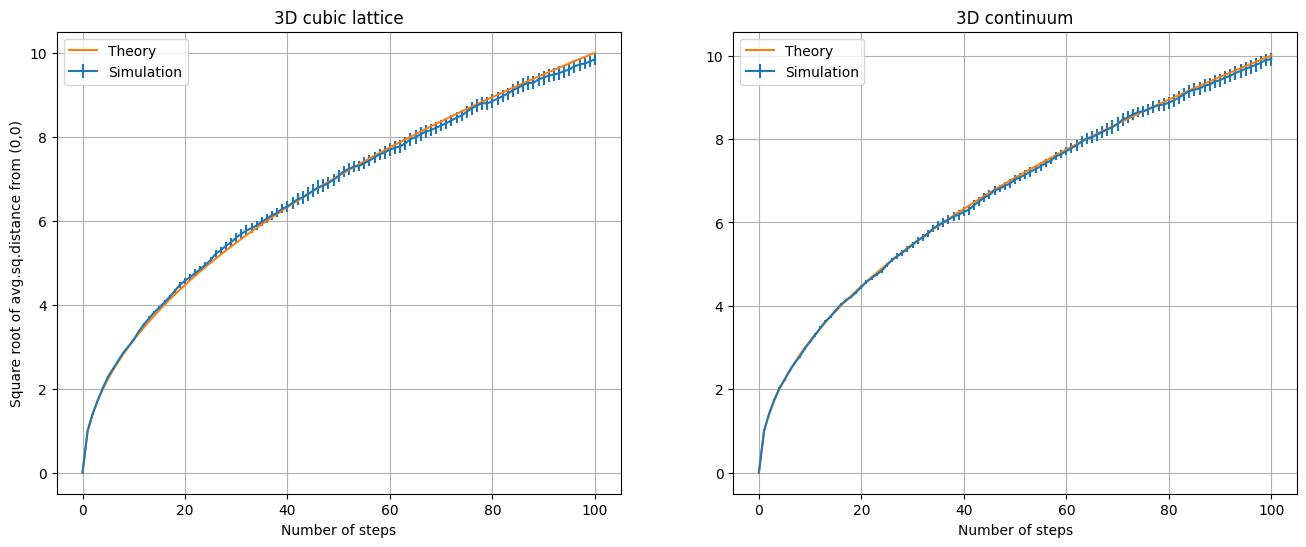

In [5]:
def f(N, k):
    return k * np.sqrt(N)

fig, axs = plt.subplots(1,2)
fig.set_figwidth(16)
fig.set_figheight(6)

axs[0].errorbar(np.arange(0, N_steps + 1), 
                rms_latt, 
                yerr=err_rms_latt,
                label="Simulation")
axs[1].errorbar(np.arange(0, N_steps + 1), 
                rms_cont, 
                yerr=err_rms_cont,
                label="Simulation")

axs[0].set_ylabel("Square root of avg.sq.distance from (0,0)")
axs[0].set_title("3D cubic lattice")
axs[1].set_title("3D continuum")

for ax in axs:
  ax.plot(np.arange(0, N_steps + 1), f(np.arange(0, N_steps + 1), a), label="Theory")
  ax.set_xlabel("Number of steps")
  ax.grid(True)
  ax.legend()
